# PRD-TCN Pushback Prediction Example

This notebook demonstrates the final pushback prediction pipeline on two hours of OpenSky data around Zurich Airport (LSZH).

The workflow is:

1. Download two hours of OpenSky history data within the LSZH area.
2. Apply the same preprocessing used for the project datasets.
3. Identify and retain departure flights only.
4. Apply the final `predict_pushback()` function to each departure with `iterate_lazy()` and `pipe()`.
5. Evaluate sequentially with `max_workers=1`.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

from traffic.core import Traffic
from traffic.data import airports, opensky


PREDICTION_FILE = next(Path.cwd().rglob("pushback_prediction.py"))
sys.path.insert(0, str(PREDICTION_FILE.parent))

from pushback_prediction import predict_pushback

## Configuration

The geographic query area is derived directly from the LSZH airport geometry and expanded by `0.1` degrees, matching the data-generation workflow.


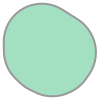

In [2]:
AIRPORT = "LSZH"
START = "2026-08-01 14:00"
STOP = "2026-08-01 15:00"

MAX_WORKERS = 1
DEVICE = "cpu"

bounds = airports[AIRPORT].shape.convex_hull.buffer(0.1)

bounds

## Download two hours of OpenSky history data

In [3]:
trajs = opensky.history(
    start=START,
    stop=STOP,
    bounds=bounds,
)

if trajs is None:
    raise RuntimeError("No OpenSky data returned for the selected interval.")

trajs

RUNNING: : 0.00% [00:06, ?%/s]
DOWNLOAD: 119klines [00:09, 12.8klines/s]


,,count
icao24,callsign,
4b180b,SWR,3599
4b5d9a,ATL783,3598
4b5d9b,ATL781,3598
4b5c65,ORION1,3597
4b1939,CSW8GJ,3593
4b17fd,SWISS,3573
4b5db2,RTT16,3486
4b5c1f,ZEBRA3,3480
4b5d98,ATL779,3403


## Preprocessing

The following preprocessing matches the project data-preparation workflow:

- normalize timestamps,
- enforce the expected column dtypes,
- assign flight IDs,
- resample each trajectory to 1 Hz.


In [4]:
def convert_timestamp(value):
    if isinstance(value, (float, int)) and value > 1e9:
        return pd.to_datetime(value, unit="s", errors="coerce")
    if isinstance(value, pd.Timestamp):
        return value
    return pd.NaT


trajs.data["timestamp"] = trajs.data["timestamp"].apply(convert_timestamp)
trajs.data["onground"] = trajs.data["onground"].astype(np.bool_)

trajs.data["latitude"] = trajs.data["latitude"].astype("double")
trajs.data["longitude"] = trajs.data["longitude"].astype("double")
trajs.data["groundspeed"] = trajs.data["groundspeed"].astype("double")
trajs.data["track"] = trajs.data["track"].astype("double")
trajs.data["vertical_rate"] = trajs.data["vertical_rate"].astype("double")
trajs.data["altitude"] = trajs.data["altitude"].astype("double")
trajs.data["geoaltitude"] = trajs.data["geoaltitude"].astype("double")

trajs.data["icao24"] = trajs.data["icao24"].astype("object")
trajs.data["callsign"] = trajs.data["callsign"].astype("object")
trajs.data["squawk"] = trajs.data["squawk"].astype("object")

trajs = trajs.assign_id().eval(
    max_workers=1,
    desc="Assigning flight IDs",
)

trajs = trajs.resample("1s").eval(
    max_workers=MAX_WORKERS,
    desc="Resampling",
)

trajs

Assigning flight IDs:   0%|          | 0/109 [00:00<?, ?it/s]

Resampling:   0%|          | 0/109 [00:00<?, ?it/s]

,count
flight_id,
SWR_042,3599
ATL783_080,3598
ATL781_081,3598
ORION1_077,3597
ATL780_084,3597
CSW8GJ_052,3593
SWISS_031,3573
TE26_088,3532
RTT16_091,3486


## Filter to departure flights

Only departures are retained before applying the pushback detector. A flight is considered a departure when `takeoff()` identifies a takeoff segment for LSZH.


In [5]:
airport_str = AIRPORT
max_workers = MAX_WORKERS


def dep_runway(flight):
    takeoff = flight.takeoff(
        airport_str,
        method="track_based",
        adv_filtering=True,
    )

    if takeoff is not None:
        next_segment = takeoff.next()
        if next_segment is not None:
            runway = next_segment.max("runway")
            return {
                "Flight ID": flight.flight_id,
                "Runway": runway,
            }


departure_runway = (
    trajs.iterate_lazy()
    .pipe(dep_runway)
    .eval(
        max_workers=max_workers,
        desc="Determining departure flights",
    )
)

if departure_runway is None:
    raise RuntimeError("No departure flights detected.")

deps = trajs[departure_runway["Flight ID"].to_list()]

deps

Determining departure flights:   0%|          | 0/109 [00:00<?, ?it/s]

/cluster/home/hanv/Projects/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/cluster/home/hanv/Projects/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/cluster/home/hanv/Projects/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/cluster/home/hanv/Projects/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/cluster/home/hanv/Projects/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/cluster/home/hanv/Projects/.v

,count
flight_id,
EDW38TD_043,2594
SWR1H_028,2379
THY1VT_092,1643
SVA232_103,1367
SWR730M_098,1303
UAE88_106,1172
EDW194_022,980
EDW330Z_048,954
EDW56Z_050,923


## Apply the final pushback prediction pipeline

`predict_pushback()` is applied independently to every flight through `pipe()`. Evaluation is kept sequential with `max_workers=1`.


In [6]:
pushbacks = (
    deps
    .iterate_lazy()
    .pipe(
        predict_pushback,
        airport=AIRPORT,
        device=DEVICE,
        cpu_threads=1,
    )
    .eval(
        max_workers=1,
        desc="Pushback prediction",
    )
)

pushbacks

Pushback prediction:   0%|          | 0/19 [00:00<?, ?it/s]

,count
flight_id,
UAE88_106,275
THY1VT_092,156
ETD140_107,138
SWR1H_028,113
EZY47ED_008,98
SWR1958_021,95
EDW194_022,93
EDW56Z_050,92
SWR4ZH_058,80


## Plot departures with detected pushback segments

The first plot shows all departure flights for which a pushback was detected.  
The complete trajectories are shown together with the corresponding detected pushback points highlighted on top.


In [7]:
if pushbacks is None:
    raise RuntimeError("No pushback segments detected.")

detected_deps = deps[pushbacks.flight_ids]

fig_detected = detected_deps.scatter_map(
    zoom=12,
    hover_data=["flight_id", "timestamp"],
)

fig_pushback = pushbacks.scatter_map(
    zoom=12,
    hover_data=["flight_id", "timestamp"],
)

for trace in fig_detected.data:
    trace.name = "Complete departure flights"
    if hasattr(trace, "marker") and trace.marker is not None:
        trace.marker.size = 5
        trace.marker.opacity = 0.35
        trace.marker.color = "blue"

for trace in fig_pushback.data:
    trace.name = "Detected pushback"
    if hasattr(trace, "marker") and trace.marker is not None:
        trace.marker.size = 8
        trace.marker.opacity = 0.95
        trace.marker.color = "red"
    fig_detected.add_trace(trace)

fig_detected.update_layout(
    title="LSZH departure flights with detected pushback segments",
)

fig_detected

## Plot departures without detected pushback

In [8]:
no_pushbacks = deps - pushbacks

no_pushbacks

,count
flight_id,
DIGRK_007,725
EDW346M_046,488
SWR2EG_026,328
MLM101_096,274


In [9]:
fig_no_pushback = no_pushbacks.scatter_map(zoom=12, hover_data=["flight_id", "timestamp"])

for trace in fig_no_pushback.data:
    trace.name = "Departure flights without detected pushback"
    if hasattr(trace, "marker") and trace.marker is not None:
        trace.marker.size = 5
        trace.marker.opacity = 0.6

fig_no_pushback.update_layout(
    title="LSZH departure flights without detected pushback",
)

fig_no_pushback